In [1]:
%pip install tensorflow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Sample sentences
sentences = [
    "the cat is sitting on mat",
    "the dog is playing in garden",
    "the cat is playing with dog",
    "the dog is sitting on floor"
]

# Create vocabulary
words = " ".join(sentences).split()
vocab = sorted(set(words))

# Create word indexes
word_to_index = {w: i for i, w in enumerate(vocab)}
index_to_word = {i: w for w, i in word_to_index.items()}

print("Vocabulary:", vocab)
print("Vocabulary Size:", len(vocab))

Vocabulary: ['cat', 'dog', 'floor', 'garden', 'in', 'is', 'mat', 'on', 'playing', 'sitting', 'the', 'with']
Vocabulary Size: 12


In [4]:
# Context window size
window = 2

X, y = [], []

for sentence in sentences:
    words = sentence.split()

    for i in range(window, len(words) - window):
        context = words[i-2:i] + words[i+1:i+3]
        target = words[i]

        X.append([word_to_index[w] for w in context])
        y.append(word_to_index[target])

X = np.array(X)
y = np.array(y)

print("Context:", X)
print("Target:", y)

Context: [[10  0  9  7]
 [ 0  5  7  6]
 [10  1  8  4]
 [ 1  5  4  3]
 [10  0  8 11]
 [ 0  5 11  1]
 [10  1  9  7]
 [ 1  5  7  2]]
Target: [5 9 5 8 5 8 5 9]


In [5]:
# Create CBOW neural network
model = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Embedding(len(vocab), 50),
    layers.GlobalAveragePooling1D(),
    layers.Dense(len(vocab), activation='softmax')
])

# Display model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 4, 50)               │             600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 50)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 12)                  │             612 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,212 (4.73 KB)

 Trainable params: 1,212 (4.73 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X, y,
    epochs=100,
    verbose=1
)

print("Model training completed!")

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 2.4784
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.2500 - loss: 2.4684
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.2500 - loss: 2.4584
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5000 - loss: 2.4484
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.6250 - loss: 2.4384
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.7500 - loss: 2.4283
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8750 - loss: 2.4183
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8750 - loss: 2.4082
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 1.0000 - loss: 2.3980
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 1.0000 - loss: 2.3878
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 1.0000 - loss: 2.3776
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 1.0000 - 

In [7]:
# Input context words
context = ["the", "cat", "on", "mat"]

# Convert words into indexes
input_data = np.array([
    [word_to_index[w] for w in context]
])

# Predict target word
prediction = model.predict(input_data, verbose=0)

# Get predicted word
index = np.argmax(prediction[0])

print("Context Words:", context)
print("Predicted Word:", index_to_word[index])

Context Words: ['the', 'cat', 'on', 'mat']
Predicted Word: is


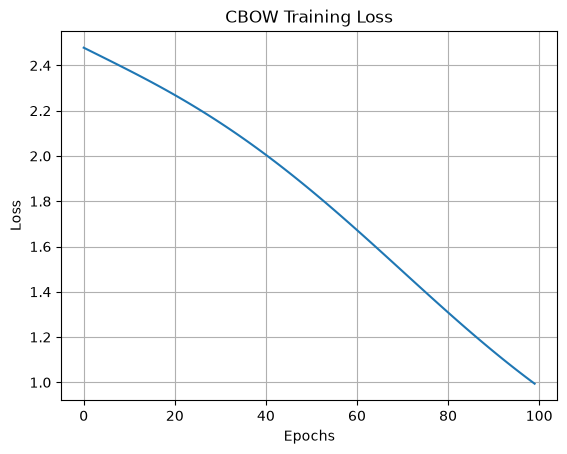

In [8]:
plt.plot(history.history['loss'])
plt.title("CBOW Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid()
plt.show()

In [9]:
print("CBOW Practical Completed Successfully!")
print("Vocabulary Size:", len(vocab))
print("Training Samples:", len(X))
print("Predicted Word:", index_to_word[index])

CBOW Practical Completed Successfully!
Vocabulary Size: 12
Training Samples: 8
Predicted Word: is
